In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()


Saving burnout_bruto.csv to burnout_bruto.csv


In [2]:

import io

nome_arquivo = "burnout_bruto.csv"

df = pd.read_csv(io.BytesIO(uploaded[nome_arquivo]))

print("Dimensões:", df.shape)
print("\nColunas:")
print(df.columns.tolist())

display(df.head())


Dimensões: (1020, 8)

Colunas:
['id_colaborador', 'nome', 'departamento', 'horas_extras', 'horas_trabalhadas', 'tickets_fora_horario', 'horario_ticket', 'nivel_clima']


,id_colaborador,nome,departamento,horas_extras,horas_trabalhadas,tickets_fora_horario,horario_ticket,nivel_clima
0,1523,Bella Camargo,Recursos Humanos,3.2,8.7,6,16:08,9.0
1,1602,Alana Cavalcante,Recursos Humanos,12.5,7.7,1,11:01,3.0
2,1526,Benício Gomes,TI,19.4,11.0,3,08h24,1.0
3,1031,Enzo Macedo,Tecnologia da Informação,15.7,10.3,1,19:12,9.0
4,1616,Henry Gabriel Sales,Comercial,15.6,10.2,4,16:40,8.0


In [3]:

# Diagnóstico da qualidade dos dados

print("=== VALORES AUSENTES ===")
display(df.isna().sum().to_frame("quantidade_ausente"))

print("=== DUPLICATAS ===")
print("Linhas completamente duplicadas:", df.duplicated().sum())
print("IDs de colaboradores únicos:", df["id_colaborador"].nunique())
print("Linhas com ID repetido:", df["id_colaborador"].duplicated().sum())

print("\n=== DEPARTAMENTOS ===")
display(df["departamento"].value_counts(dropna=False).to_frame("quantidade"))

print("\n=== ESTATÍSTICAS ===")
display(
    df[[
        "horas_extras",
        "horas_trabalhadas",
        "tickets_fora_horario",
        "nivel_clima"
    ]].describe().round(2)
)

print("\n=== VALORES DE NIVEL_CLIMA ===")
display(df["nivel_clima"].value_counts(dropna=False).sort_index().to_frame("quantidade"))


=== VALORES AUSENTES ===


,quantidade_ausente
id_colaborador,0
nome,0
departamento,0
horas_extras,50
horas_trabalhadas,0
tickets_fora_horario,0
horario_ticket,30
nivel_clima,51


=== DUPLICATAS ===
Linhas completamente duplicadas: 19
IDs de colaboradores únicos: 1000
Linhas com ID repetido: 20

=== DEPARTAMENTOS ===


,quantidade
departamento,
Tecnologia da Informação,124
Financeiro,124
ti,124
Comercial,117
RH,116
Operacoes,110
Recursos Humanos,108
Operações,105
TI,92



=== ESTATÍSTICAS ===


,horas_extras,horas_trabalhadas,tickets_fora_horario,nivel_clima
count,970.00,1020.00,1020.00,969.00
mean,11.98,8.54,2.93,5.44
std,5.70,1.52,1.68,2.87
min,0.00,4.20,0.00,1.00
25%,7.72,7.50,2.00,3.00
50%,11.95,8.50,3.00,5.00
75%,15.88,9.50,4.00,8.00
max,28.40,13.20,9.00,10.00



=== VALORES DE NIVEL_CLIMA ===


,quantidade
nivel_clima,
1.0,91
2.0,115
3.0,97
4.0,97
5.0,99
6.0,88
7.0,79
8.0,113
9.0,113


In [4]:
import pandas as pd
import unicodedata

# Criar uma cópia para preservar a base original
df_limpo = df.copy()

# 1. Remover somente linhas completamente duplicadas
duplicatas = df_limpo.duplicated().sum()
df_limpo = df_limpo.drop_duplicates().copy()

# 2. Padronizar os nomes dos departamentos
def normalizar_texto(texto):
    texto = str(texto).strip().lower()
    texto = unicodedata.normalize("NFKD", texto)
    texto = "".join(
        caractere for caractere in texto
        if not unicodedata.combining(caractere)
    )
    return texto

def padronizar_departamento(valor):
    texto = normalizar_texto(valor)

    if texto in ["ti", "tecnologia da informacao"]:
        return "TI"
    elif texto in ["rh", "recursos humanos"]:
        return "Recursos Humanos"
    elif texto == "operacoes":
        return "Operacoes"
    elif texto == "financeiro":
        return "Financeiro"
    elif texto == "comercial":
        return "Comercial"
    else:
        return valor

df_limpo["departamento"] = (
    df_limpo["departamento"].apply(padronizar_departamento)
)

# 3. Padronizar os horários de tickets
df_limpo["horario_ticket"] = (
    df_limpo["horario_ticket"]
    .astype("string")
    .str.strip()
    .str.replace(r"(?i)^(\d{1,2})h(\d{2})$", r"\1:\2", regex=True)
)

# 4. Conferir o resultado
print("Linhas originais:", len(df))
print("Duplicatas completas removidas:", duplicatas)
print("Linhas após limpeza:", len(df_limpo))

print("\nDepartamentos padronizados:")
print(df_limpo["departamento"].value_counts().to_string())

print("\nValores ausentes:")
print(df_limpo.isna().sum().to_string())

Linhas originais: 1020
Duplicatas completas removidas: 19
Linhas após limpeza: 1001

Departamentos padronizados:
departamento
TI                  333
Recursos Humanos    220
Operacoes           212
Financeiro          121
Comercial           115

Valores ausentes:
id_colaborador           0
nome                     0
departamento             0
horas_extras            50
horas_trabalhadas        0
tickets_fora_horario     0
horario_ticket          30
nivel_clima             50


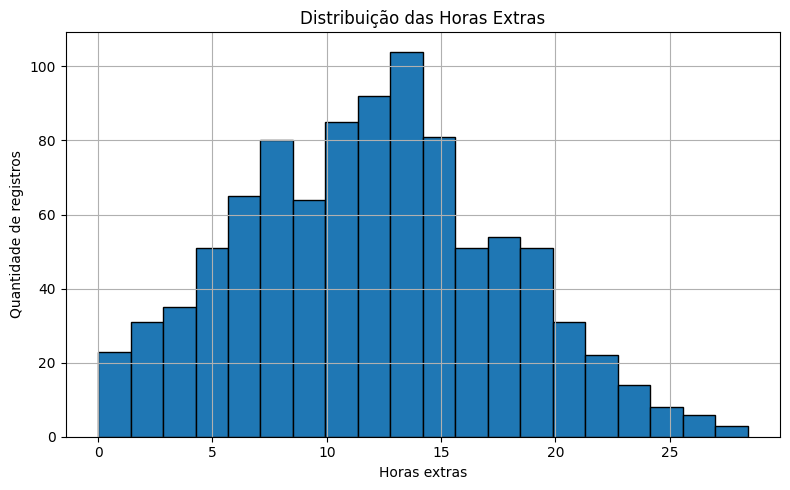

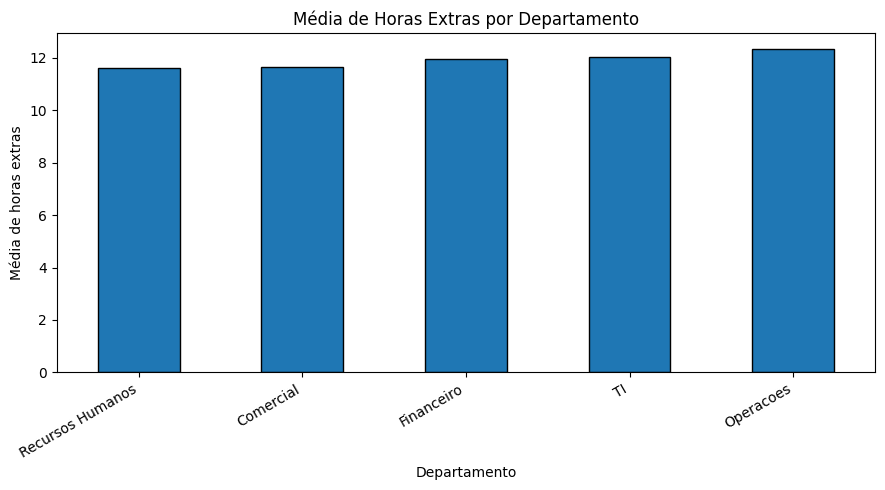

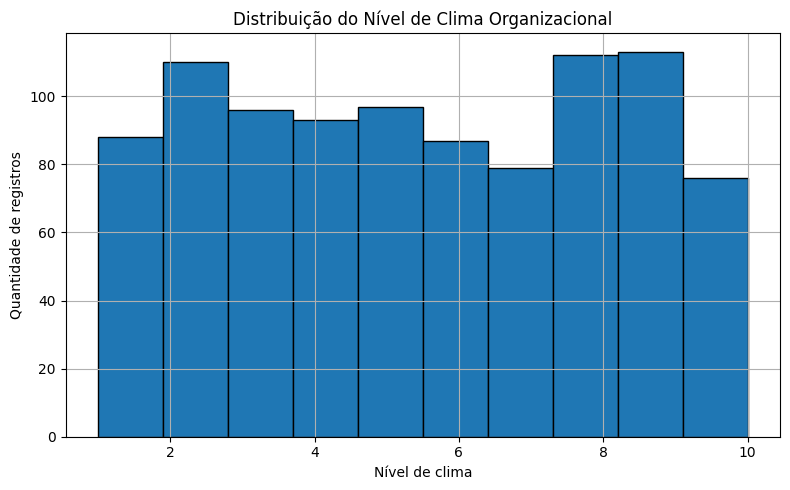

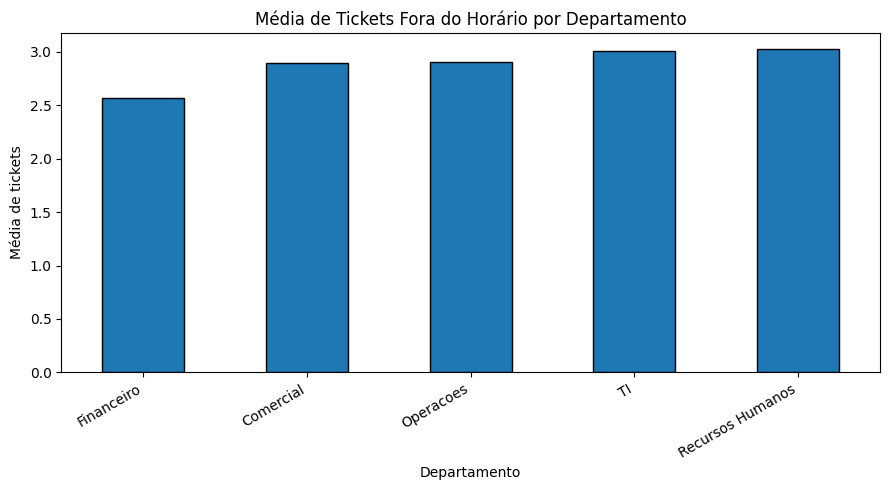

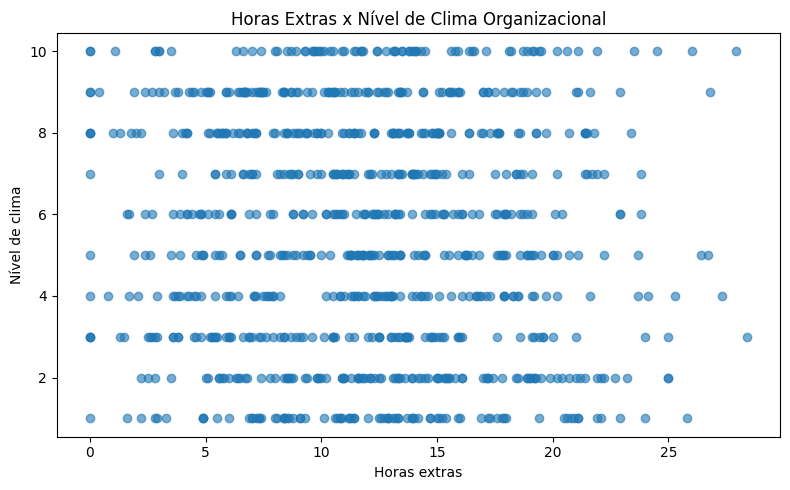

Os cinco gráficos foram gerados e salvos na pasta graficos_burnout.


In [5]:

import matplotlib.pyplot as plt
import pandas as pd

# Garantir que as colunas numéricas estejam no formato correto
colunas_numericas = [
    "horas_extras",
    "horas_trabalhadas",
    "tickets_fora_horario",
    "nivel_clima"
]

for coluna in colunas_numericas:
    df_limpo[coluna] = pd.to_numeric(
        df_limpo[coluna], errors="coerce"
    )

# Criar pasta para salvar os gráficos
import os
os.makedirs("graficos_burnout", exist_ok=True)

# Gráfico 1 — Distribuição das horas extras
plt.figure(figsize=(8, 5))
df_limpo["horas_extras"].dropna().hist(bins=20, edgecolor="black")
plt.title("Distribuição das Horas Extras")
plt.xlabel("Horas extras")
plt.ylabel("Quantidade de registros")
plt.tight_layout()
plt.savefig("graficos_burnout/01_horas_extras.png", dpi=150)
plt.show()

# Gráfico 2 — Média de horas extras por departamento
plt.figure(figsize=(9, 5))
(
    df_limpo.groupby("departamento")["horas_extras"]
    .mean()
    .sort_values()
    .plot(kind="bar", edgecolor="black")
)
plt.title("Média de Horas Extras por Departamento")
plt.xlabel("Departamento")
plt.ylabel("Média de horas extras")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("graficos_burnout/02_horas_extras_departamento.png", dpi=150)
plt.show()

# Gráfico 3 — Distribuição do nível de clima organizacional
plt.figure(figsize=(8, 5))
(
    df_limpo["nivel_clima"]
    .dropna()
    .hist(bins=10, edgecolor="black")
)
plt.title("Distribuição do Nível de Clima Organizacional")
plt.xlabel("Nível de clima")
plt.ylabel("Quantidade de registros")
plt.tight_layout()
plt.savefig("graficos_burnout/03_nivel_clima.png", dpi=150)
plt.show()

# Gráfico 4 — Média de tickets fora do horário por departamento
plt.figure(figsize=(9, 5))
(
    df_limpo.groupby("departamento")["tickets_fora_horario"]
    .mean()
    .sort_values()
    .plot(kind="bar", edgecolor="black")
)
plt.title("Média de Tickets Fora do Horário por Departamento")
plt.xlabel("Departamento")
plt.ylabel("Média de tickets")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("graficos_burnout/04_tickets_departamento.png", dpi=150)
plt.show()

# Gráfico 5 — Relação entre horas extras e clima
plt.figure(figsize=(8, 5))
plt.scatter(
    df_limpo["horas_extras"],
    df_limpo["nivel_clima"],
    alpha=0.6
)
plt.title("Horas Extras x Nível de Clima Organizacional")
plt.xlabel("Horas extras")
plt.ylabel("Nível de clima")
plt.tight_layout()
plt.savefig("graficos_burnout/05_horas_extras_clima.png", dpi=150)
plt.show()

print("Os cinco gráficos foram gerados e salvos na pasta graficos_burnout.")


In [6]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Selecionar as colunas que serão utilizadas
colunas_features = [
    "departamento",
    "horas_extras",
    "horas_trabalhadas",
    "tickets_fora_horario"
]

# O modelo só pode ser treinado em linhas com o alvo conhecido
dados_modelo = df_limpo[
    colunas_features + ["nivel_clima"]
].copy()

dados_modelo["nivel_clima"] = pd.to_numeric(
    dados_modelo["nivel_clima"], errors="coerce"
)

dados_modelo = dados_modelo.dropna(subset=["nivel_clima"])

X = dados_modelo[colunas_features]
y = dados_modelo["nivel_clima"]

# 2. Separar treino e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# 3. Tratar as colunas numéricas
colunas_num = [
    "horas_extras",
    "horas_trabalhadas",
    "tickets_fora_horario"
]

tratamento_num = Pipeline(steps=[
    ("imputacao", SimpleImputer(strategy="median"))
])

# 4. Tratar a coluna categórica
tratamento_cat = Pipeline(steps=[
    ("imputacao", SimpleImputer(strategy="most_frequent")),
    ("codificacao", OneHotEncoder(handle_unknown="ignore"))
])

preprocessamento = ColumnTransformer(transformers=[
    ("numericas", tratamento_num, colunas_num),
    ("categoricas", tratamento_cat, ["departamento"])
])

# 5. Criar o modelo Random Forest
modelo = Pipeline(steps=[
    ("preprocessamento", preprocessamento),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        min_samples_leaf=3
    ))
])

# 6. Treinar o modelo
modelo.fit(X_treino, y_treino)

# 7. Fazer previsões no conjunto de teste
previsoes = modelo.predict(X_teste)

# 8. Criar uma previsão de referência para comparação
modelo_referencia = DummyRegressor(strategy="mean")
modelo_referencia.fit(X_treino, y_treino)
previsoes_referencia = modelo_referencia.predict(X_teste)

# 9. Avaliar os resultados
def avaliar_modelo(nome, real, previsto):
    mae = mean_absolute_error(real, previsto)
    rmse = np.sqrt(mean_squared_error(real, previsto))
    r2 = r2_score(real, previsto)

    return {
        "Modelo": nome,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    }

resultados = pd.DataFrame([
    avaliar_modelo("Random Forest", y_teste, previsoes),
    avaliar_modelo("Referência (média)", y_teste, previsoes_referencia)
])

print("Registros disponíveis para modelagem:", len(dados_modelo))
print("Registros para treinamento:", len(X_treino))
print("Registros para teste:", len(X_teste))

display(resultados.round(3))


Registros disponíveis para modelagem: 951
Registros para treinamento: 760
Registros para teste: 191


,Modelo,MAE,RMSE,R²
0,Random Forest,2.418,2.842,-0.118
1,Referência (média),2.348,2.715,-0.020


Matriz de correlação:


,horas_extras,horas_trabalhadas,tickets_fora_horario,nivel_clima
horas_extras,1.000,0.025,-0.046,-0.047
horas_trabalhadas,0.025,1.000,0.007,0.030
tickets_fora_horario,-0.046,0.007,1.000,-0.076
nivel_clima,-0.047,0.030,-0.076,1.000


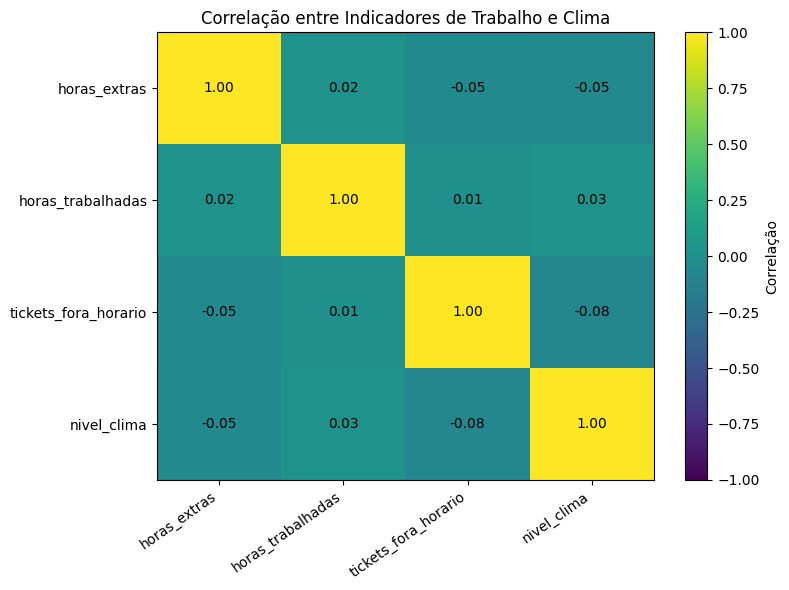

In [7]:

import matplotlib.pyplot as plt
import numpy as np

colunas = [
    "horas_extras",
    "horas_trabalhadas",
    "tickets_fora_horario",
    "nivel_clima"
]

correlacao = df_limpo[colunas].corr()

print("Matriz de correlação:")
display(correlacao.round(3))

plt.figure(figsize=(8, 6))
plt.imshow(correlacao, vmin=-1, vmax=1, aspect="auto")
plt.colorbar(label="Correlação")
plt.xticks(range(len(colunas)), colunas, rotation=35, ha="right")
plt.yticks(range(len(colunas)), colunas)

for i in range(len(colunas)):
    for j in range(len(colunas)):
        valor = correlacao.iloc[i, j]
        plt.text(j, i, f"{valor:.2f}", ha="center", va="center")

plt.title("Correlação entre Indicadores de Trabalho e Clima")
plt.tight_layout()
plt.savefig("graficos_burnout/06_matriz_correlacao.png", dpi=150)
plt.show()


In [8]:

from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Reutilizar o pré-processamento da etapa anterior
modelo_linear = Pipeline(steps=[
    ("preprocessamento", clone(preprocessamento)),
    ("regressor", LinearRegression())
])

# Treinar e prever
modelo_linear.fit(X_treino, y_treino)
previsoes_linear = modelo_linear.predict(X_teste)

# Comparar os três modelos
def calcular_metricas(nome, real, previsto):
    return {
        "Modelo": nome,
        "MAE": mean_absolute_error(real, previsto),
        "RMSE": np.sqrt(mean_squared_error(real, previsto)),
        "R²": r2_score(real, previsto)
    }

comparacao = pd.DataFrame([
    calcular_metricas("Random Forest", y_teste, previsoes),
    calcular_metricas("Regressão Linear", y_teste, previsoes_linear),
    calcular_metricas(
        "Referência (média)",
        y_teste,
        previsoes_referencia
    )
])

display(comparacao.round(3))


,Modelo,MAE,RMSE,R²
0,Random Forest,2.418,2.842,-0.118
1,Regressão Linear,2.380,2.762,-0.056
2,Referência (média),2.348,2.715,-0.020
